In [75]:
import time 
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import randint, uniform, loguniform
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

# Feature Analysis Notebook

Which isotope features actually influence a model's prediction? Do these relationships make sense?

From the previous investigations, we had a feature list that was initially just 3 parameters: Z number, A number and energy, and all models we tested used Z as the most important feature. When we added 10 features, nothing changed, in fact a lot of models performed worse, especially after look-alikes were removed. This was perhaps due to the new features introduced being exclusive to a spefiic isotope, which doesn't really give the model a lot of information to predict cross-sections, just gives it better data to identify an isotope.  

We can append the AME to our EXFOR data in order to increase the number of features

In [63]:
## Importing data:


D = Path("/Msci Project/Msci-Project/ML 4 Nuclear Data/ML 4 Nuclear Data/data/teaching")
db = pd.read_csv(D / "capture_cleaned.csv")
ev = pd.read_csv(D / "endf_Au197_capture.csv")

db["logE"], db["logS"] = np.log10(db.energy_eV), np.log10(db.sigma_b * 1000)    ### logS is what we want to predict
db["iso"] = db.Z * 1000 + db.A                                                  ### We give each isotope a unique number so we can use in validation
base_features = ["Z", "A", "logE"]

## We are also interested in appending AME data

cols = ["N","Z","A","el","orig","ME","ME_unc","BE_A","BE_A_unc","beta_type","Qbeta","Qbeta_unc"]
cs = [(4,9),(9,14),(14,19),(20,23),(23,27),(28,42),(42,54),(54,67),(68,78),(79,81),(81,94),(94,105)]

ame = pd.read_fwf("mass_1.mas20.txt", colspecs=cs ,names=cols, skiprows=36)

for c in ["N", "Z", "A"]:
    ame[c] = ame[c].astype(int)

ame["extrapolated"] = ame["ME"].str.contains("#")

for c in ["ME", "ME_unc", "BE_A", "BE_A_unc", "Qbeta", "Qbeta_unc"]:
    ame[c] = pd.to_numeric(ame[c].str.replace("#", ".", regex=False), errors="coerce")


ME = ame.set_index(["Z","A"])["ME"]

MEn, MEp, MEa = ME[(0,1)], ME[(1,1)], ME[(2,4)]

me = lambda z, a:ME.get((z,a), np.nan)


In [64]:
# --- load AME (as before) ---
cols = ["N","Z","A","el","orig","ME","ME_unc","BE_A","BE_A_unc","beta_type","Qbeta","Qbeta_unc"]
cs = [(4,9),(9,14),(14,19),(20,23),(23,27),(28,42),(42,54),(54,67),(68,78),(79,81),(81,94),(94,105)]

ame = pd.read_fwf("mass_1.mas20.txt", colspecs=cs, names=cols, skiprows=36, dtype=str)

for c in ["N","Z","A"]: ame[c] = ame[c].astype(int)     ### Converting to integers

ame["extrapolated"] = ame["ME"].str.contains("#")                                               ## 
for c in ["ME","ME_unc","BE_A","BE_A_unc","Qbeta","Qbeta_unc"]: 
    ame[c] = pd.to_numeric(ame[c].str.replace("#", ".", regex=False), errors="coerce")          ## Converting mass index to numerical value 

ME = ame.set_index(["Z","A"])["ME"]                                             ## Mass lookup table indexed by Z and A to give easy mass excess values
MEn, MEp, MEa = ME[(0,1)], ME[(1,1)], ME[(2,4)]
v = np.vectorize(lambda z, a: ME.get((z, a), np.nan))

# --- merge target properties ---
ex = db
ex = ex.merge(
    ame[["Z","A","ME","ME_unc","BE_A","Qbeta","extrapolated"]].rename(columns={                                   ## Merging the two EXFOR and AME datasets
        "ME":"ME_target","ME_unc":"ME_target_unc","BE_A":"BE_per_A",
        "Qbeta":"Qbeta_target","extrapolated":"target_extrap"}),
    on=["Z","A"], how="left")

z, a = ex.Z.values, ex.A.values
ex["N"] = a - z
ex["N_minus_Z"] = ex.N - z
ex["asym"] = ex.N_minus_Z / a

# --- separation energies and the capture Q-value (keV) ---
ex["Sn_target"] = v(z, a-1)   - ex.ME_target + MEn
ex["Sp_target"] = v(z-1, a-1) - ex.ME_target + MEp
ex["Sa_target"] = v(z-2, a-4) - ex.ME_target + MEa
ex["Q_ng"]      = ex.ME_target + MEn - v(z, a+1)        # = Sn of the compound nucleus

# --- energy-dependent features ---
ex["E_cm_keV"]        = ex.energy_eV/1e3 * a/(a+1)
ex["Ex_compound_keV"] = ex.Q_ng + ex.E_cm_keV            # excitation energy of A+1

# --- structure features ---
ex["parity"] = np.select([(z%2==0)&(ex.N%2==0), (z%2==1)&(ex.N%2==1)], [0, 2], 1)  # 0 even-even, 1 odd-A, 2 odd-odd
magic = np.array([2,8,20,28,50,82,126])
ex["dist_magic_N"] = [np.abs(magic-n).min() for n in ex.N]
ex["dist_magic_Z"] = [np.abs(magic-zz).min() for zz in z]

magic_N = np.array([2,8,20,28,50,82,126])
magic_Z = np.array([2,8,20,28,50,82])

ex["dist_magic_N"] = [                                      ## Distances from magic numbers, apparently might be useful?
    np.abs(magic_N - n).min() for n in ex.N
]

ex["dist_magic_Z"] = [
    np.abs(magic_Z - zz).min() for zz in z
]

In [65]:
ex.head()

,entry,Z,A,energy_eV,sigma_b,logE,logS,iso,ME_target,ME_target_unc,...,asym,Sn_target,Sp_target,Sa_target,Q_ng,E_cm_keV,Ex_compound_keV,parity,dist_magic_N,dist_magic_Z
0,11235005,5,11,139000.0,0.000008,5.143015,-2.091515,5011,8667.708,0.012,...,0.090909,11454.22106,11228.750064,8664.3125,3369.62806,127.416667,3497.044727,1,2,3
1,11235005,5,11,198000.0,0.000013,5.296665,-1.896196,5011,8667.708,0.012,...,0.090909,11454.22106,11228.750064,8664.3125,3369.62806,181.500000,3551.128060,1,2,3
2,11235005,5,11,238000.0,0.000010,5.376577,-1.978811,5011,8667.708,0.012,...,0.090909,11454.22106,11228.750064,8664.3125,3369.62806,218.166667,3587.794727,1,2,3
3,11235005,5,11,287000.0,0.000010,5.457882,-1.987163,5011,8667.708,0.012,...,0.090909,11454.22106,11228.750064,8664.3125,3369.62806,263.083333,3632.711393,1,2,3
4,11235005,5,11,336000.0,0.000016,5.526339,-1.801343,5011,8667.708,0.012,...,0.090909,11454.22106,11228.750064,8664.3125,3369.62806,308.000000,3677.628060,1,2,3


We want to know, does incorporating further nuclear structure + energetic properties improve the decision tree model? 

In [67]:
## Defining different feature sets that we are interested in testing:

energetic_features = [
    "Sn_target",
    "Sp_target",
    "Sa_target",
    "Q_ng",
    "Ex_compound_keV"
]

structure_features = [
    "N_minus_Z",
    "asym",
    "parity",
    "dist_magic_N",
    "dist_magic_Z"
]

## All the new features:
ame_features = energetic_features + structure_features

## Four experiments:
feature_sets = {
    "Baseline" : base_features,
    "Energetics" : base_features + energetic_features,
    "Structure" : base_features + structure_features,
    "Combined" : base_features + ame_features
}

for name, feats in feature_sets.items():
    print(name, feats)


Baseline ['Z', 'A', 'logE']
Energetics ['Z', 'A', 'logE', 'Sn_target', 'Sp_target', 'Sa_target', 'Q_ng', 'Ex_compound_keV']
Structure ['Z', 'A', 'logE', 'N_minus_Z', 'asym', 'parity', 'dist_magic_N', 'dist_magic_Z']
Combined ['Z', 'A', 'logE', 'Sn_target', 'Sp_target', 'Sa_target', 'Q_ng', 'Ex_compound_keV', 'N_minus_Z', 'asym', 'parity', 'dist_magic_N', 'dist_magic_Z']


In [82]:
## Holding out gold again...

test = ex[
    (ex["Z"] == 79) & (ex["A"] == 197)
].copy()

train = ex.drop(test.index).copy()

print(f"No of.Training Measuremetnts = {len(train)}")
print(f"No. of Gold test measurements = {len(test)}")
print(f"No. of Training isotopes = {train.groupby(["Z", "A"]).ngroups}")

## Now training the tree..

tree = DecisionTreeRegressor(criterion="squared_error", max_depth=8, min_samples_leaf=5, random_state=0)

## Cleaning the data:

all_features = list(dict.fromkeys(
    base_features + ame_features
))

train_clean = train.dropna(
    subset = all_features + ["logS"]
).copy()

test_clean = test.dropna(
    subset=all_features + ["logS"]
).copy()

print("----------------")
print(f"No. original gold measurements: {len(test)}")
print(f"No. of usable gold measurements: {len(test_clean)}")

No of.Training Measuremetnts = 7324
No. of Gold test measurements = 300
No. of Training isotopes = 82
----------------
No. original gold measurements: 300
No. of usable gold measurements: 300


                RMSE  RMS factor  Median factor
Baseline    0.109309    1.286201       1.153036
Energetics  0.156862    1.435034       1.241717
Structure   0.140257    1.381202       1.277393
Combined    0.160415    1.446822       1.345423


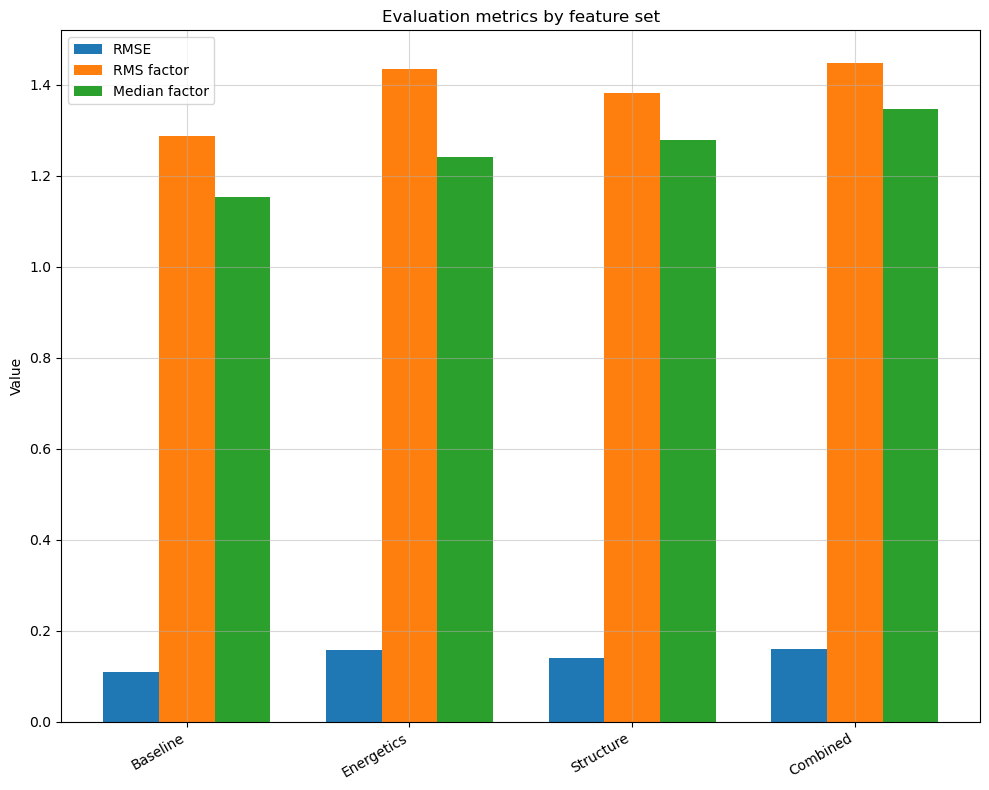

In [115]:
## Define model evaluation function:

def evaluate(model, x, y):

    predictions = model.predict(x)
    residuals = predictions - y
    rmse = np.sqrt(mean_squared_error(y, predictions))
    rms_factor = 10 ** np.sqrt(np.mean(residuals**2))
    median_factor = 10 ** np.median(np.abs(residuals))

    return {
        "RMSE" : rmse,
        "RMS factor": rms_factor,
        "Median factor" : median_factor
    }

## Training model and evaluating:
results = {}
models = {}

for name, feats in feature_sets.items():

    model = DecisionTreeRegressor(criterion="squared_error", max_depth=8, min_samples_leaf=5, random_state=0)
    model.fit(train_clean[feats], train_clean["logS"])

    metrics = evaluate(model, test_clean[feats], test_clean["logS"])

    results[name] = metrics
    models[name] = model

results_df = pd.DataFrame(results).T

print(results_df)

# Plot all evaluation metrics for each feature set
metrics_to_plot = ["RMSE", "RMS factor", "Median factor"]
feature_names = results_df.index.tolist()
x = np.arange(len(feature_names))
width = 0.25

plt.figure(figsize=(10, 8))
for i, metric in enumerate(metrics_to_plot):
    plt.bar(x + (i - 1) * width, results_df[metric].values, width=width, label=metric)

plt.xticks(x, feature_names, rotation=30, ha="right")
plt.ylabel("Value")
plt.title("Evaluation metrics by feature set")
plt.legend()
plt.tight_layout()
plt.grid(alpha=0.5)
plt.show()

We see that for the gold example, the RMS factor is actually the best for the baseline feature set, and is worse with more features

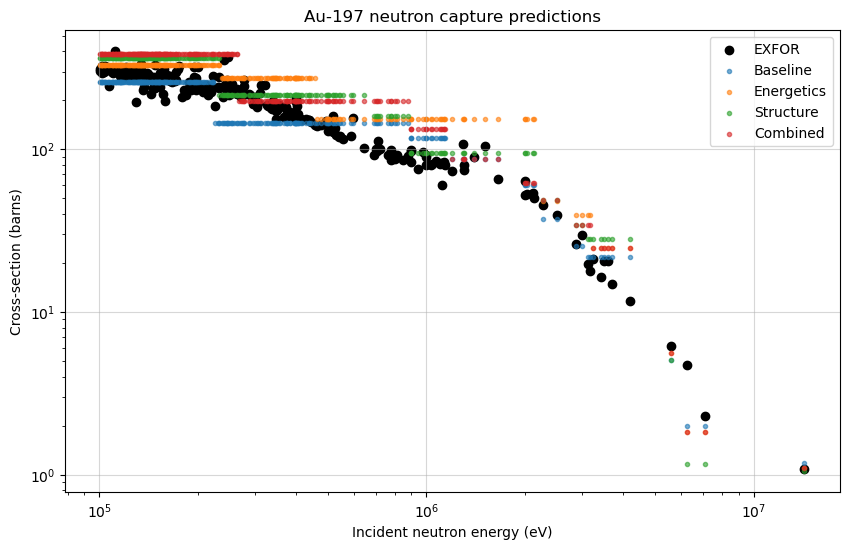

In [114]:
plt.figure(figsize=(10, 6))

# Experimental measurements
plt.scatter(
    test_clean["energy_eV"],
    10**test_clean["logS"],
    label="EXFOR",
    color="black",
    alpha=1
)

for name, model in models.items():

    feats = feature_sets[name]

    predicted = model.predict(test_clean[feats])

    plt.scatter(
        test_clean["energy_eV"],
        10**predicted,
        marker=".",
        label=name,
        alpha=0.6,
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Incident neutron energy (eV)")
plt.ylabel("Cross-section (barns)")

plt.title("Au-197 neutron capture predictions")
plt.grid(alpha=0.5)
plt.legend()
plt.show()

## Investigating SHAP

SHAP attempts to quantify how much each feature contributes to a prediction relative to a reference prediction

$$ f(x) = E[f(X)] +  \sum_i{\phi_i}$$

- $f(x)$ is model prediction
- $E[f(X)]$ is expected model prediction across the reference dataset
- $\phi_i$ is the SHAP contribution of feature $i$

Positive SHAP value pushes the predicted cross-section value upwards, negative downwards

Our target is logS, so SHAP values will be expressed in log cross-section units

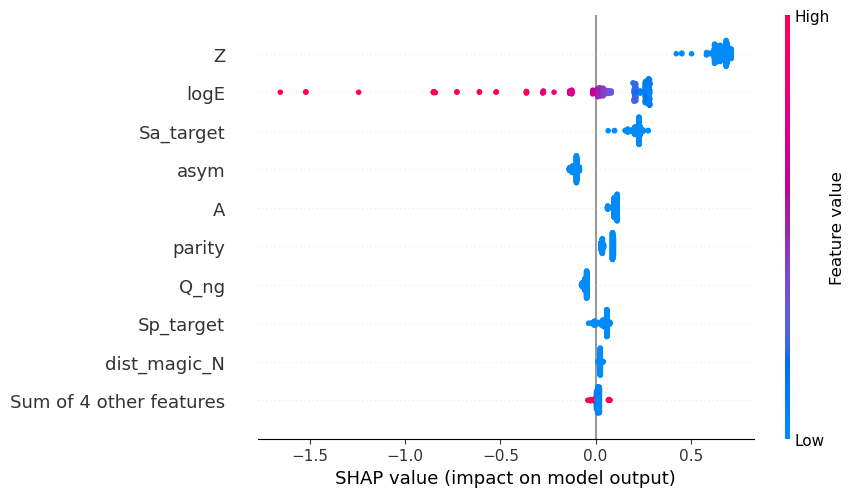

In [118]:
import shap

model = models["Combined"]

X_train = train_clean[feature_sets["Combined"]]
X_test = test_clean[feature_sets["Combined"]]

explainer = shap.TreeExplainer(model)

shap_values = explainer(X_test)

shap.plots.beeswarm(shap_values)

Features are ranked by their mean absolute SHAP values: features at the top have the greatest overall contribution to predictiosn in the dataset being explained

Horizontal position shows whether a feature pushes predictions higher or lower

The colour represents actual feature value

Can also investigate SHAP dependence plots for individual features:

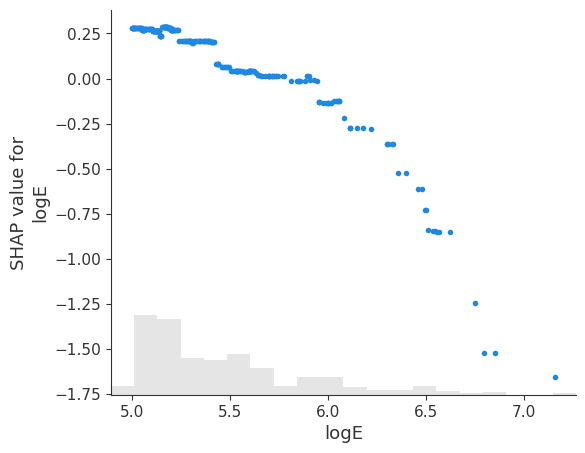

In [123]:
shap.plots.scatter(
    shap_values[:, "logE"]
)

$\textbf{Note:}$ In our experiment here, we are testing one isotope, therefore a lot of features are constant across the entire dataset, such as Z and A (Structure). SHAP cannot tell us how these features influence predictions across different isotopes, but can tell us how their particular values contribute to gold predictions relative to the training reference population.

We would need to do SHAP analysis across multiple isotopes to understand general model behaviour

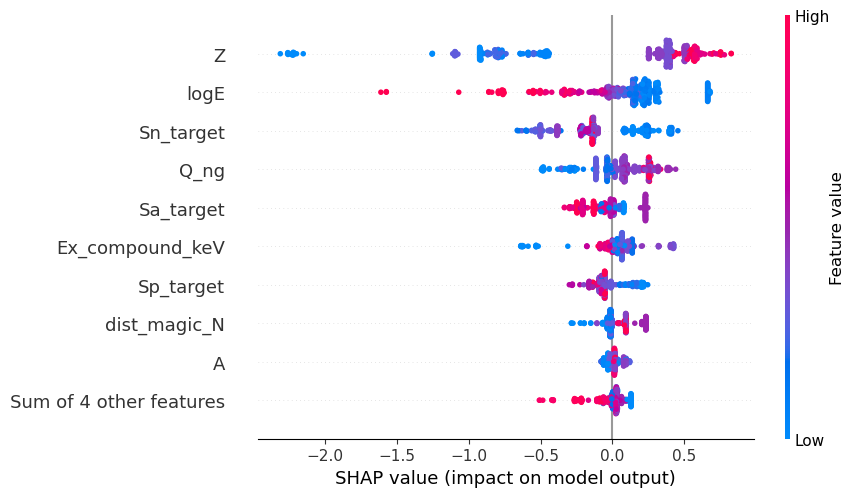

In [125]:
from sklearn.model_selection import GroupShuffleSplit

# Use the combined feature set
feats = feature_sets["Combined"]

X = train_clean[feats]
y = train_clean["logS"]

# Identify isotopes
groups = (
    train_clean["Z"].astype(str) + "_" +
    train_clean["A"].astype(str)
)

# Split by isotope, not individual measurement
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups)
)

X_fit = X.iloc[train_idx]
y_fit = y.iloc[train_idx]

X_val = X.iloc[val_idx]

# Train model
global_model = DecisionTreeRegressor(
    criterion="squared_error",
    max_depth=8,
    min_samples_leaf=5,
    random_state=0
)

global_model.fit(X_fit, y_fit)

# Sample validation measurements for SHAP
X_shap = X_val.sample(
    n=min(500, len(X_val)),
    random_state=0
)

# SHAP analysis
global_explainer = shap.TreeExplainer(global_model)

global_shap_values = global_explainer(X_shap)

shap.plots.beeswarm(global_shap_values)

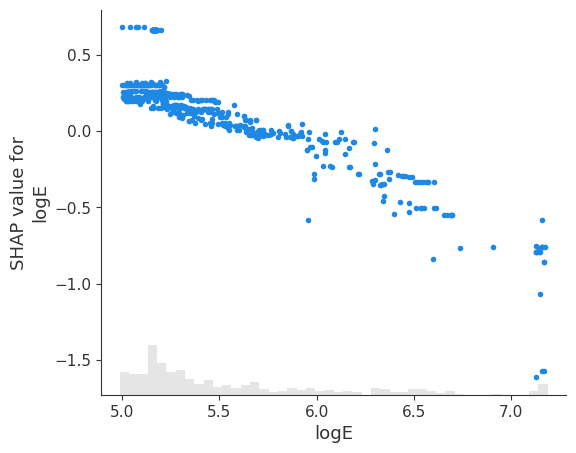

In [135]:
shap.plots.scatter(
    global_shap_values[:, "logE"]
)

## Investigating LIME 

Lime = Local Interpretable Model-agnostic Explanations

It attempts to explain individual predictions and can be aggregated to describe global model behaviour

It specifically tries to explain one prediction at a time

LIME approximates the complicated model with a much simpler model in the vicinity of one particular prediction

In [129]:
#pip install lime

from lime.lime_tabular import LimeTabularExplainer

model = models["Combined"]

feats = feature_sets["Combined"]

X_train = train_clean[feats]
X_test = test_clean[feats]

## Initialising LIME

explainer = LimeTabularExplainer(
    training_data = X_train.values,
    feature_names = feats,
    mode = "regression",
    discretize_continuous = True,
    random_state=0
)

## Calculate prediction:
predictions = model.predict(X_test)

## Measurement with largest abs error:
errors = np.abs(predictions - test_clean["logS"].values)

worst_idx = np.argmax(errors)

# Select that observation
observation = X_test.iloc[worst_idx]

print("Incident energy:",
      test_clean["energy_eV"].iloc[worst_idx])

print("Experimental logS:",
      test_clean["logS"].iloc[worst_idx])

print("Predicted logS:",
      predictions[worst_idx])

print("Absolute error:", errors[worst_idx])

Incident energy: 6250000.0
Experimental logS: 0.6720978579357175
Predicted logS: 0.2626190661023258
Absolute error: 0.4094787918333917


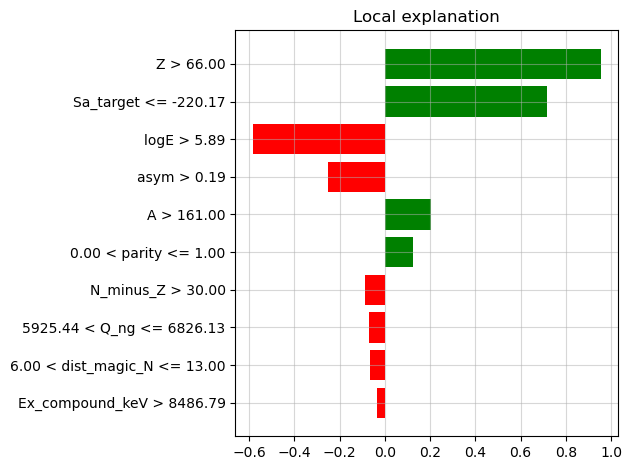

In [134]:
## Now want LIME to explain why this prediction was made

fig = exp.as_pyplot_figure()

plt.tight_layout()
plt.grid(alpha=0.5)
plt.show()